In [5]:
# =========================
# Standard library imports
# =========================
import os
import hashlib
import sys
import subprocess
import shutil
import tarfile
import zipfile
import pickle
import random
from pathlib import Path
from datetime import datetime
from io import BytesIO
import urllib.request
from tqdm.auto import tqdm
import time
from concurrent.futures import ThreadPoolExecutor

# =========================
# Third-party libraries
# =========================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pycocotools.coco import COCO
import albumentations as A

# =========================
# Cloud / data access
# =========================
import boto3
import kagglehub

random.seed(42)

In [6]:
# Pull default bucket from store
%store -r bucket
bucket = bucket
print(bucket)

s3 = boto3.client("s3")

sagemaker-us-east-1-298748835671


# Clean Working Folders
Every run starts from empty working folders under `data/raw` and `data/processed`. Images are re-encoded in place during ingestion, and anything left from an earlier run would be scanned again. One earlier run ingested every Kaggle cat image twice this way: the previous download was still on disk, the new one was nested inside it, and the two copies were split independently, putting the same image in both training and test.

Downloaded archives in `data/downloads` are never modified, so they are kept and reused.

In [ ]:
DOWNLOAD_DIR = Path("data/downloads")

for folder in ("data/raw", "data/processed", "data/temp_cats"):
    shutil.rmtree(folder, ignore_errors=True)

Path("data/raw").mkdir(parents=True)
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

# Image Normalization
Every image is re-encoded as an RGB JPEG at the same quality before upload. The original sources were compressed very differently: the Kaggle cats had a median file size about a third of COCO's. A classifier could learn that difference instead of learning what a cat looks like.

Images are re-encoded in place. To start again from the original files, download them again.

In [7]:
JPEG_QUALITY = 90


def normalize_jpeg(path) -> bool:
    """Re-encode an image in place as an RGB JPEG at JPEG_QUALITY. Returns False if unreadable."""
    try:
        with Image.open(path) as img:
            rgb = img.convert("RGB")
        rgb.save(path, format="JPEG", quality=JPEG_QUALITY)
        return True
    except Exception as e:
        tqdm.write(f"[SKIP] {path}: {e}")
        return False


def file_hash(path) -> str:
    """MD5 of a file's bytes. Identical images re-encode to identical bytes, so equal
    hashes mean the same picture appears twice."""
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()


def normalize_images(paths) -> list[str]:
    """Normalize many images in parallel; returns the paths that succeeded."""
    paths = [str(path) for path in paths]
    with ThreadPoolExecutor(max_workers=8) as pool:
        succeeded = list(tqdm(pool.map(normalize_jpeg, paths), total=len(paths),
                              desc="Normalizing images", unit="img"))
    return [path for path, ok in zip(paths, succeeded) if ok]

# Downloading Raw Cat Images and Annotations from Kagglehub

In [8]:
temp_dir = "data/temp_cats"
path = kagglehub.dataset_download(handle="crawford/cat-dataset", 
                                  output_dir=temp_dir, 
                                  force_download=True)

100%|██████████| 4.04G/4.04G [00:28<00:00, 151MB/s] 

Extracting files...


In [9]:
# move cats images folder to raw. If the destination already existed, shutil.move would
# nest the new download inside it, so the clean-up step above must have run.
assert not Path("data/raw/cats").exists(), "data/raw/cats already exists; run the clean-up cell first"
shutil.move(f"{temp_dir}/cats", "data/raw/cats", copy_function=shutil.copy2)

'data/raw/cats/cats'

In [10]:
# delete unneeded files from kaggle download
try:
    shutil.rmtree(temp_dir)
    print(f"Directory '{temp_dir}' and all its contents deleted.")
except FileNotFoundError:
    print("Error: Directory not found.")
except Exception as e:
    print(f"Error deleting directory: {e}")

Directory 'data/temp_cats' and all its contents deleted.


In [11]:
kaggle_cat_images = sorted(Path("data/raw/cats").rglob("*.jpg"))
normalized_kaggle = normalize_images(kaggle_cat_images)
print(f"Normalized {len(normalized_kaggle)} of {len(kaggle_cat_images)} Kaggle cat images")

Normalizing images:   0%|          | 0/27990 [00:00<?, ?img/s]

Normalized 27990 of 27990 Kaggle cat images


# Parsing Annotation Files

In [12]:
raw_dir_prefix = "data/raw"
raw_dir = Path(f"{raw_dir_prefix}/cats")
processed_dir = Path("data/processed/cats")
processed_dir.mkdir(parents=True, exist_ok=True)
remote_path_prefix = f"s3://{bucket}/cat-landmarks-project"

rows = []

for img_path in raw_dir.rglob("*.jpg"):
    # Example: annotation file might be "<image>.cat" or similar naming
    ann_path = img_path.with_suffix(img_path.suffix + ".cat")

    if not ann_path.exists():
        continue

    # Read and parse annotation file
    text = ann_path.read_text().strip().split()
    pts = np.array(list(map(float, text[1:])))
    x_idxs = [0, 2, 4, 6, 8, 10, 12, 14, 16]
    y_idxs = [x + 1 for x in x_idxs]
    coord_pairs = [[int(x), int(y)] for x, y in zip(pts[x_idxs], pts[y_idxs])]
    
    remote_path = f"{remote_path_prefix}/{img_path}"

    rows.append({"remote_path":str(remote_path), "local_path": str(img_path), "points": coord_pairs})

cats_ann = pd.DataFrame(rows)

# Expand pts into columns
landmark_features = [     
              "left_eye", 
              "right_eye", 
              "mouth",   
              "left_ear_1", 
              "left_ear_2", 
              "left_ear_3", 
              "right_ear_1", 
              "right_ear_2", 
              "right_ear_3", 
              ]

cats_ann[landmark_features] = pd.DataFrame(cats_ann["points"].to_list())
cats_ann = cats_ann.drop(columns=["points"])
cats_ann.head()

,remote_path,local_path,left_eye,right_eye,mouth,left_ear_1,left_ear_2,left_ear_3,right_ear_1,right_ear_2,right_ear_3
0,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_000.jpg,"[175, 160]","[239, 162]","[199, 199]","[149, 121]","[137, 78]","[166, 93]","[281, 101]","[312, 96]","[296, 133]"
1,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_005.jpg,"[96, 96]","[153, 127]","[103, 146]","[48, 20]","[78, -37]","[127, 5]","[210, 52]","[260, 63]","[229, 121]"
2,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_008.jpg,"[318, 222]","[340, 224]","[327, 238]","[301, 199]","[304, 182]","[321, 196]","[341, 197]","[359, 183]","[361, 203]"
3,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_011.jpg,"[167, 173]","[242, 185]","[191, 247]","[112, 105]","[118, 0]","[171, 74]","[270, 90]","[353, 35]","[332, 147]"
4,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_012.jpg,"[115, 122]","[179, 121]","[133, 169]","[95, 70]","[93, 17]","[131, 46]","[233, 39]","[281, 9]","[224, 69]"


In [ ]:
# Exact duplicate images would leak between splits, so keep one copy of each.
# Sorting first makes the row order, and so the random split below, reproducible.
cats_ann = cats_ann.sort_values("local_path").reset_index(drop=True)
cats_ann["content_hash"] = [file_hash(path) for path in tqdm(cats_ann["local_path"], desc="Hashing Kaggle cat images", unit="img")]

duplicates = cats_ann["content_hash"].duplicated()
print(f"Kaggle cat images: {len(cats_ann)} annotated, {duplicates.sum()} exact duplicates removed")
cats_ann = cats_ann[~duplicates].reset_index(drop=True)

# Data Splitting

In [13]:
cats_ann["version"] = cats_ann["local_path"].apply(lambda _: "raw")
n = cats_ann.shape[0]

np.random.seed(42)
n_train = int(0.4 * n)
n_test = int(0.1 * n)
n_val = int(0.1 * n)
n_prod = n - n_train - n_test - n_val

splits = (
    ["train"] * n_train +
    ["test"] * n_test +
    ["validation"] * n_val +
    ["production"] * n_prod
)

np.random.shuffle(splits)
cats_ann["split"] = splits
cats_ann["split"].value_counts()

split
production    7999
train         7997
validation    1999
test          1999
Name: count, dtype: int64

# Image Augmentation

In [14]:
def augmentation_pipeline(
    src_df: pd.DataFrame,
    local_path_key: str,
    remote_path_key: str,
    coord_cols: list[str],
    metadata_headers: list[str],
    suffix: str,
    split: str,
    composition: A.Compose,
    keypoint_permutation: list[int] | None = None,
) -> pd.DataFrame:

    image_srcs = src_df[local_path_key].values
    output_rows = []

    for img in tqdm(image_srcs, desc="Augmenting images", unit="img"):
        try:
            raw_image = Image.open(img)

            row = (
                src_df.loc[src_df[local_path_key] == img, coord_cols]
                .iloc[0]
            )

            keypoints = np.stack(row.to_list()).astype(np.float32)

            augmentation = composition(
                image=np.asarray(raw_image, dtype=np.uint8),
                keypoints=keypoints,
            )
            
            aug_name = f"{img.split(".")[0]}_{suffix}.jpg"
            aug_keypoints = augmentation["keypoints"].astype(np.int32).tolist()
            if keypoint_permutation is not None:
                aug_keypoints = [aug_keypoints[i] for i in keypoint_permutation]
            aug_image_jpg = Image.fromarray(
                augmentation["image"]
            ).convert("RGB")
            
            remote_path = src_df[remote_path_key][src_df[local_path_key] == img].values[0]
            aug_remote_path = f"{remote_path.split(".")[0]}_{suffix}.jpg"

            aug_row = {
                **dict(zip(coord_cols, aug_keypoints)),
                "remote_path": aug_remote_path,
                "local_path": aug_name,
                "version": suffix,
                "split": split,
            }

            output_rows.append(aug_row)
            aug_image_jpg.save(aug_name, quality=JPEG_QUALITY)

        except Exception as e:
            tqdm.write(f"[ERROR] {img}: {e}")

    output_df = pd.DataFrame(output_rows, columns=metadata_headers)
    return output_df


In [15]:
# A horizontal flip mirrors the face, so left/right landmark names must be swapped
# to keep each name on the same anatomical point. Ear points are annotated in a
# consistent rotational order (ear_1 -> ear_2 -> ear_3), which a mirror reverses.
mirror_landmark_map = {
    "left_eye": "right_eye", "right_eye": "left_eye", "mouth": "mouth",
    "left_ear_1": "right_ear_3", "left_ear_2": "right_ear_2", "left_ear_3": "right_ear_1",
    "right_ear_1": "left_ear_3", "right_ear_2": "left_ear_2", "right_ear_3": "left_ear_1",
}
mirror_permutation = [landmark_features.index(mirror_landmark_map[name]) for name in landmark_features]

# Version 2 Image Augmentations
cat_aug_v2 = A.Compose(
    [
        A.HorizontalFlip(p=1),
        # Light per-pixel grain: noise with a standard deviation of 2-5% of the pixel range
        A.GaussNoise(std_range=(0.02, 0.05), p=1),
    ],
    keypoint_params=A.KeypointParams(format="xy", remove_invisible=False),
    seed=42,
)

# Version 3 Image Augmentations
# Small rotations, scale changes and lighting changes, the variation upright cat photos
# actually have. Rotation and scaling don't mirror the face, so no relabeling is needed.
cat_aug_v3 = A.Compose(
    [
        A.Affine(rotate=(-15, 15), scale=(0.9, 1.1), p=1),
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=1),
    ],
    keypoint_params=A.KeypointParams(format="xy", remove_invisible=False),
    seed=42,
)

# Only augmenting Training data
aug_df = cats_ann[(cats_ann["split"]=="train") & (cats_ann["version"]=="raw")]
print(aug_df.shape)

(7997, 13)


In [16]:
aug_meta_v2 = augmentation_pipeline(aug_df, 
                      local_path_key="local_path", 
                      remote_path_key="remote_path",
                      coord_cols=landmark_features,
                      metadata_headers=cats_ann.columns, 
                      split="train",
                      suffix="v2", 
                      composition=cat_aug_v2,
                      keypoint_permutation=mirror_permutation)

Augmenting images:   0%|          | 0/7997 [00:00<?, ?img/s]

In [17]:
aug_meta_v2.head()

,remote_path,local_path,left_eye,right_eye,mouth,left_ear_1,left_ear_2,left_ear_3,right_ear_1,right_ear_2,right_ear_3,version,split
0,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_005_v2.jpg,"[346, 127]","[403, 96]","[396, 146]","[270, 121]","[239, 63]","[289, 52]","[372, 5]","[421, -37]","[451, 20]",v2,train
1,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_008_v2.jpg,"[159, 224]","[181, 222]","[172, 238]","[138, 203]","[140, 183]","[158, 197]","[178, 196]","[195, 182]","[198, 199]",v2,train
2,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_017_v2.jpg,"[512, 344]","[613, 464]","[455, 494]","[547, 200]","[686, 75]","[643, 250]","[735, 359]","[910, 370]","[801, 473]",v2,train
3,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_020_v2.jpg,"[162, 139]","[274, 125]","[249, 200]","[88, 124]","[37, 51]","[139, 79]","[262, 60]","[330, 12]","[313, 93]",v2,train
4,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000002_003_v2.jpg,"[328, 340]","[530, 399]","[360, 504]","[212, 232]","[253, -28]","[384, 171]","[635, 262]","[931, 190]","[747, 413]",v2,train


In [18]:
aug_meta_v3 = augmentation_pipeline(aug_df, 
                      local_path_key="local_path", 
                      remote_path_key="remote_path",
                      coord_cols=landmark_features,
                      metadata_headers=cats_ann.columns, 
                      split="train",
                      suffix="v3", 
                      composition=cat_aug_v3)

Augmenting images:   0%|          | 0/7997 [00:00<?, ?img/s]

In [19]:
# Combining metadata
cats_ann_combined = pd.concat([cats_ann, aug_meta_v2, aug_meta_v3], ignore_index=True)

print(cats_ann.shape)
print(cats_ann_combined.shape)

cats_ann_combined.head()

(19994, 13)
(35988, 13)


,remote_path,local_path,left_eye,right_eye,mouth,left_ear_1,left_ear_2,left_ear_3,right_ear_1,right_ear_2,right_ear_3,version,split
0,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_000.jpg,"[175, 160]","[239, 162]","[199, 199]","[149, 121]","[137, 78]","[166, 93]","[281, 101]","[312, 96]","[296, 133]",raw,production
1,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_005.jpg,"[96, 96]","[153, 127]","[103, 146]","[48, 20]","[78, -37]","[127, 5]","[210, 52]","[260, 63]","[229, 121]",raw,train
2,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_008.jpg,"[318, 222]","[340, 224]","[327, 238]","[301, 199]","[304, 182]","[321, 196]","[341, 197]","[359, 183]","[361, 203]",raw,train
3,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_011.jpg,"[167, 173]","[242, 185]","[191, 247]","[112, 105]","[118, 0]","[171, 74]","[270, 90]","[353, 35]","[332, 147]",raw,production
4,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_012.jpg,"[115, 122]","[179, 121]","[133, 169]","[95, 70]","[93, 17]","[131, 46]","[233, 39]","[281, 9]","[224, 69]",raw,validation


In [20]:
cats_ann_combined["split"].value_counts()

split
train         23991
production     7999
validation     1999
test           1999
Name: count, dtype: int64

In [21]:
# Expanding coordinates into individual feature columns for modeling
def get_x_coord(coord_pair: object):
    return coord_pair[0]

def get_y_coord(coord_pair: object):
    return coord_pair[1]

for feature in landmark_features:
    x_feat_name = feature + "_x"
    y_feat_name = feature + "_y"
    
    cats_ann_combined[x_feat_name] = cats_ann_combined[feature].apply(get_x_coord)
    cats_ann_combined[y_feat_name] = cats_ann_combined[feature].apply(get_y_coord)

cats_ann_combined.head()

,remote_path,local_path,left_eye,right_eye,mouth,left_ear_1,left_ear_2,left_ear_3,right_ear_1,right_ear_2,...,left_ear_2_x,left_ear_2_y,left_ear_3_x,left_ear_3_y,right_ear_1_x,right_ear_1_y,right_ear_2_x,right_ear_2_y,right_ear_3_x,right_ear_3_y
0,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_000.jpg,"[175, 160]","[239, 162]","[199, 199]","[149, 121]","[137, 78]","[166, 93]","[281, 101]","[312, 96]",...,137,78,166,93,281,101,312,96,296,133
1,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_005.jpg,"[96, 96]","[153, 127]","[103, 146]","[48, 20]","[78, -37]","[127, 5]","[210, 52]","[260, 63]",...,78,-37,127,5,210,52,260,63,229,121
2,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_008.jpg,"[318, 222]","[340, 224]","[327, 238]","[301, 199]","[304, 182]","[321, 196]","[341, 197]","[359, 183]",...,304,182,321,196,341,197,359,183,361,203
3,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_011.jpg,"[167, 173]","[242, 185]","[191, 247]","[112, 105]","[118, 0]","[171, 74]","[270, 90]","[353, 35]",...,118,0,171,74,270,90,353,35,332,147
4,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_012.jpg,"[115, 122]","[179, 121]","[133, 169]","[95, 70]","[93, 17]","[131, 46]","[233, 39]","[281, 9]",...,93,17,131,46,233,39,281,9,224,69


# Checking Image Variants

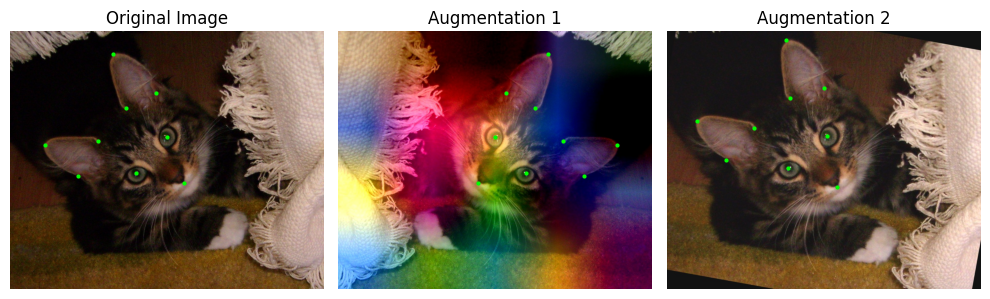

In [22]:
# The first training image (only training images are augmented) and its two augmented versions
example_path = aug_df["local_path"].iloc[0]
image_paths = [Path(example_path)] + [Path(f"{example_path.split('.')[0]}_{suffix}.jpg") for suffix in ("v2", "v3")]

TITLES = [
    "Original Image",
    "Augmentation 1",
    "Augmentation 2",
]

def load_image_and_keypoints(image_path: Path, ann_df: pd.DataFrame):
    image = Image.open(image_path)

    keypoints = (
        ann_df[landmark_features]
        .loc[ann_df["local_path"] == str(image_path)]
        .iloc[0]
        .values
    )

    x_vals = [pt[0] for pt in keypoints]
    y_vals = [pt[1] for pt in keypoints]

    return image, x_vals, y_vals


fig, axes = plt.subplots(1, len(image_paths), figsize=(10, 4))

for ax, image_path, title in zip(axes, image_paths, TITLES):
    image, x_vals, y_vals = load_image_and_keypoints(image_path, cats_ann_combined)

    ax.imshow(image)
    ax.scatter(x_vals, y_vals, s=4, c="lime")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Downloading COCO Images
COCO supplies both classes: scenes without cats (negatives) and scenes with cats (positives). Drawing both classes from the same source means the classifier cannot separate cats from non-cats by image source alone.

In [23]:
# Setting up COCO directories: the annotations archive is cached in data/downloads,
# images are downloaded into the working folder
noncats_dir = Path("data/raw/noncats")
noncats_dir.mkdir(parents=True, exist_ok=True)

coco_download_dir = DOWNLOAD_DIR / "coco"
coco_download_dir.mkdir(parents=True, exist_ok=True)
ann_dir = coco_download_dir / "annotations"
ann_zip_path = coco_download_dir / "annotations_trainval2017.zip"

ann_zip_path

PosixPath('data/raw/noncats/annotations_trainval2017.zip')

In [24]:
# Download Annotations
coco_ann_zip_url = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"

# Downloaded once and reused; the .part file means an interrupted download is never cached
if not ann_zip_path.exists():
    partial = ann_zip_path.with_name(ann_zip_path.name + ".part")
    urllib.request.urlretrieve(coco_ann_zip_url, partial)
    partial.rename(ann_zip_path)

if not ann_dir.exists():
    with zipfile.ZipFile(ann_zip_path, "r") as z:
        z.extractall(coco_download_dir)

# Load annotations
instances_json = ann_dir / "instances_train2017.json"
coco = COCO(str(instances_json))

# Get category id for "cat" images
cat_id = coco.getCatIds(catNms=["cat"])[0]

# Image IDs that contain at least one cat
cat_img_ids = set(coco.getImgIds(catIds=[cat_id]))

# All training image IDs
all_img_ids = set(coco.getImgIds())

# Non-cat image IDs
noncat_img_ids = list(all_img_ids - cat_img_ids)

loading annotations into memory...
Done (t=12.17s)
creating index...
index created!


In [25]:
NUM_NONCAT_IMAGES = 15_000
MAX_RESTARTS = 5
SLEEP_BETWEEN_RESTARTS = 5
BASE_URL = "http://images.cocodataset.org/train2017"

random.seed(42)

coco_noncat_dir = noncats_dir / "noncat_images"
coco_cat_dir = Path("data/raw/coco_cats")


def get_downloaded_img_ids(directory: Path) -> set[int]:
    """Return set of COCO image IDs already downloaded."""
    ids = set()
    for fname in os.listdir(directory):
        stem = Path(fname).stem
        if stem.isdigit():
            ids.add(int(stem.lstrip("0") or "0"))
    return ids


def download_coco_images(img_ids, out_dir: Path, desc: str):
    """Download COCO train2017 images by ID. Restart-safe: files already present are skipped."""
    out_dir.mkdir(parents=True, exist_ok=True)
    img_by_id = {img["id"]: img for img in coco.loadImgs(list(img_ids))}

    def download(img):
        dst = out_dir / img["file_name"]
        tmp = dst.with_name(dst.name + ".part")
        try:
            urllib.request.urlretrieve(f"{BASE_URL}/{img['file_name']}", tmp)
            tmp.rename(dst)  # only complete files count as downloaded
            return None
        except Exception:
            return img["id"]

    remaining_ids = set(img_ids)
    for attempt in range(1, MAX_RESTARTS + 1):
        remaining_ids -= get_downloaded_img_ids(out_dir)
        if not remaining_ids:
            break
        print(f"Attempt {attempt}/{MAX_RESTARTS}: {len(remaining_ids)} images remaining")
        with ThreadPoolExecutor(max_workers=16) as pool:
            results = pool.map(download, [img_by_id[i] for i in remaining_ids])
            failed = [i for i in tqdm(results, total=len(remaining_ids), desc=desc, unit="image") if i is not None]
        remaining_ids = set(failed)
        if remaining_ids:
            time.sleep(SLEEP_BETWEEN_RESTARTS)

    if remaining_ids:
        print(f"⚠️ {len(remaining_ids)} images could not be downloaded after {MAX_RESTARTS} attempts.")
    else:
        print(f"✅ All {len(img_ids)} images downloaded to {out_dir}.")


# Negatives: a random sample of images that contain no cat
noncat_sample_ids = random.sample(sorted(noncat_img_ids), k=NUM_NONCAT_IMAGES)
download_coco_images(noncat_sample_ids, coco_noncat_dir, desc="Downloading COCO non-cat images")

Attempt 1/5: 15000 images remaining


✅ All 15000 images downloaded to data/raw/noncats/noncat_images.


In [26]:
# Positives: every train2017 image that contains a cat
download_coco_images(sorted(cat_img_ids), coco_cat_dir, desc="Downloading COCO cat images")

Attempt 1/5: 4114 images remaining


✅ All 4114 images downloaded to data/raw/coco_cats.


In [27]:
normalized_coco = set(normalize_images(
    sorted(coco_noncat_dir.glob("*.jpg")) + sorted(coco_cat_dir.glob("*.jpg"))
))

Normalizing images:   0%|          | 0/19114 [00:00<?, ?img/s]

# Downloading Oxford-IIIT Pet Images
The Oxford-IIIT Pet dataset (CC BY-SA 4.0) has 12 cat breeds and 25 dog breeds photographed in similar settings. Its dogs are hard negatives, close to cat photos in framing and subject. Its cats are positives from the same source.

In [28]:
pets_dir = Path("data/raw/oxford_pets")
pets_download_dir = DOWNLOAD_DIR / "oxford_pets"
pets_download_dir.mkdir(parents=True, exist_ok=True)
PETS_BASE_URL = "https://www.robots.ox.ac.uk/~vgg/data/pets/data"

# Archives are downloaded once and reused; images are extracted fresh into the working folder
for archive in ("images.tar.gz", "annotations.tar.gz"):
    archive_path = pets_download_dir / archive
    if not archive_path.exists():
        partial = archive_path.with_name(archive + ".part")
        urllib.request.urlretrieve(f"{PETS_BASE_URL}/{archive}", partial)
        partial.rename(archive_path)
    with tarfile.open(archive_path, "r:gz") as tar:
        tar.extractall(pets_dir)

/tmp/ipykernel_674/1392182443.py:10: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(pets_dir)


In [29]:
# annotations/list.txt: "<image> <class id> <species> <breed id>", species 1 = cat, 2 = dog
pets_list = pd.read_csv(
    pets_dir / "annotations" / "list.txt",
    sep=" ", comment="#", header=None,
    names=["image", "class_id", "species", "breed_id"],
)
pets_list["local_path"] = pets_list["image"].apply(lambda name: str(pets_dir / "images" / f"{name}.jpg"))
pets_list["label"] = (pets_list["species"] == 1).astype(int)

# A few files in the archive are not readable images; those are dropped
normalized_pets = set(normalize_images(pets_list["local_path"]))
pets_list = pets_list[pets_list["local_path"].isin(normalized_pets)].reset_index(drop=True)
pets_list["label"].value_counts().rename({1: "cat", 0: "dog"})

Normalizing images:   0%|          | 0/7349 [00:00<?, ?img/s]

label
dog    4978
cat    2371
Name: count, dtype: int64

# Building File Manifest

In [30]:
def get_image_metadata(img_path: str) -> tuple[int | None, int | None, int | None]:
    try:
        img = Image.open(Path(img_path))
        width, height = img.size
        file_size = os.stat(img_path).st_size

        return file_size, width, height
    except Exception:
        return None, None, None

In [31]:
cats_ann_combined[["file_size", "width", "height"]] = cats_ann_combined["local_path"].apply(get_image_metadata).to_list()
cats_ann_combined["label"] = 1
cats_ann_combined["source"] = "kaggle_cats"

cats_ann_combined.head()

,remote_path,local_path,left_eye,right_eye,mouth,left_ear_1,left_ear_2,left_ear_3,right_ear_1,right_ear_2,...,right_ear_1_y,right_ear_2_x,right_ear_2_y,right_ear_3_x,right_ear_3_y,file_size,width,height,label,source
0,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_000.jpg,"[175, 160]","[239, 162]","[199, 199]","[149, 121]","[137, 78]","[166, 93]","[281, 101]","[312, 96]",...,101,312,96,296,133,62131,375,500,1,kaggle_cats
1,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_005.jpg,"[96, 96]","[153, 127]","[103, 146]","[48, 20]","[78, -37]","[127, 5]","[210, 52]","[260, 63]",...,52,260,63,229,121,53517,500,375,1,kaggle_cats
2,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_008.jpg,"[318, 222]","[340, 224]","[327, 238]","[301, 199]","[304, 182]","[321, 196]","[341, 197]","[359, 183]",...,197,359,183,361,203,82097,500,375,1,kaggle_cats
3,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_011.jpg,"[167, 173]","[242, 185]","[191, 247]","[112, 105]","[118, 0]","[171, 74]","[270, 90]","[353, 35]",...,90,353,35,332,147,72250,500,375,1,kaggle_cats
4,s3://sagemaker-us-east-1-298748835671/cat-land...,data/raw/cats/CAT_00/00000001_012.jpg,"[115, 122]","[179, 121]","[133, 169]","[95, 70]","[93, 17]","[131, 46]","[233, 39]","[281, 9]",...,39,281,9,224,69,41119,500,333,1,kaggle_cats


In [32]:
SPLIT_FRACTIONS = {"train": 0.4, "test": 0.1, "validation": 0.1, "production": 0.4}


def assign_splits(df: pd.DataFrame, seed: int = 42) -> pd.Series:
    """Same 40/10/10/40 train/test/validation/production split as the Kaggle cats,
    stratified by label so every split keeps the source's class mix."""
    rng = np.random.default_rng(seed)
    splits = pd.Series(index=df.index, dtype="object")
    for _, group in df.groupby("label"):
        n = len(group)
        counts = {name: int(fraction * n) for name, fraction in SPLIT_FRACTIONS.items()}
        counts["production"] = n - counts["train"] - counts["test"] - counts["validation"]
        labels = np.concatenate([[name] * count for name, count in counts.items()])
        rng.shuffle(labels)
        splits.loc[group.index] = labels
    return splits


# Hashes of every original image already in the manifest, starting with the Kaggle cats
seen_hashes = set(cats_ann["content_hash"])


def build_metadata(local_paths, labels, source: str) -> pd.DataFrame:
    df = pd.DataFrame({"local_path": [str(path) for path in local_paths], "label": list(labels)})

    # Exact duplicates, within this source or of an image already in the manifest,
    # would leak between splits, so keep only the first copy
    df["content_hash"] = [file_hash(path) for path in tqdm(df["local_path"], desc=f"Hashing {source} images", unit="img")]
    duplicate = df["content_hash"].duplicated() | df["content_hash"].isin(seen_hashes)
    print(f"{source}: {len(df)} images, {duplicate.sum()} exact duplicates removed")
    df = df[~duplicate].reset_index(drop=True)
    seen_hashes.update(df["content_hash"])

    df["remote_path"] = df["local_path"].apply(lambda path: f"{remote_path_prefix}/{path}")
    df[["file_size", "width", "height"]] = df["local_path"].apply(get_image_metadata).to_list()
    df["source"] = source
    df["version"] = "raw"
    df["split"] = assign_splits(df)
    return df


coco_noncat_paths = [path for path in map(str, sorted(coco_noncat_dir.glob("*.jpg"))) if path in normalized_coco]
coco_cat_paths = [path for path in map(str, sorted(coco_cat_dir.glob("*.jpg"))) if path in normalized_coco]

coco_metadata = build_metadata(
    coco_noncat_paths + coco_cat_paths,
    [0] * len(coco_noncat_paths) + [1] * len(coco_cat_paths),
    source="coco",
)
oxford_metadata = build_metadata(pets_list["local_path"], pets_list["label"], source="oxford_pets")

In [33]:
manifest_columns = ["remote_path", "local_path", "file_size", "width", "height",
                    "label", "source", "version", "split"]

combined_image_catalogue = pd.concat(
    [cats_ann_combined[manifest_columns], coco_metadata[manifest_columns], oxford_metadata[manifest_columns]],
    ignore_index=True,
)
# Athena reads these as BIGINT; failing here is better than a type error in a query later
combined_image_catalogue = combined_image_catalogue.astype({"file_size": "int64", "width": "int64", "height": "int64"})
combined_image_catalogue["ingest_time"] = datetime.now().isoformat()

# Every original image appears exactly once, so no image can sit in two splits
original_hashes = pd.concat([cats_ann["content_hash"], coco_metadata["content_hash"], oxford_metadata["content_hash"]])
assert original_hashes.is_unique, "the same image appears more than once in the manifest"

combined_image_catalogue.groupby(["source", "label", "split"]).size().unstack("split")

split              production  test  train  validation
source      label                                     
coco        0            6000  1500   6000        1500
            1            1647   411   1645         411
kaggle_cats 1            7999  1999  23991        1999
oxford_pets 0            1993   497   1991         497
            1             949   237    948         237

# Upload Metadata to S3

In [34]:
# Save artifacts to disk
combined_processed_dir = Path("data/processed/combined/")
combined_processed_dir.mkdir(parents=True, exist_ok=True)

cats_ann_combined.to_csv("data/processed/cats/annotations.csv", index=False)
cats_ann_combined.to_parquet("data/processed/cats/annotations.pqt", index=False)

combined_image_catalogue.to_csv(
    combined_processed_dir / "combined_metadata.csv", index=False
)
combined_image_catalogue.to_parquet(
    combined_processed_dir / "combined_metadata.pqt", index=False
)

# Upload the locally generated annotations file to S3
annotations_dest_path = "cat-landmarks-project/data/processed/cats/annotations"
s3.upload_file(
    "data/processed/cats/annotations.pqt",
    bucket,
    f"{annotations_dest_path}/annotations.pqt",
)

# Upload combined metadata file to S3
combined_metadata_dest_path = "cat-landmarks-project/data/processed/combined/metadata"
s3.upload_file(
    combined_processed_dir / "combined_metadata.pqt",
    bucket,
    f"{combined_metadata_dest_path}/combined_metadata.pqt",
)

# Upload Images to S3

In [35]:
# Uploading images
def upload_image(paths):
    local_path, remote_path = paths
    try:
        s3.upload_file(local_path, bucket, remote_path.replace(f"s3://{bucket}/", ""))
        return None
    except Exception as e:
        tqdm.write(f"[ERROR] {e} - file: {local_path}")
        return local_path

image_paths = list(zip(combined_image_catalogue["local_path"], combined_image_catalogue["remote_path"]))
with ThreadPoolExecutor(max_workers=16) as pool:
    results = pool.map(upload_image, image_paths)
    failed_uploads = [path for path in tqdm(results, total=len(image_paths), desc="Uploading images to S3", unit="image") if path]

# Every image in the manifest must be in S3 before the training pipelines read it
if failed_uploads:
    raise RuntimeError(f"{len(failed_uploads)} images failed to upload")

Uploading images to S3:   0%|          | 0/62451 [00:00<?, ?image/s]

In [36]:
# Project-level S3 locations
project_prefix = "cat-landmarks-project"
s3_raw_cats_prefix = f"s3://{bucket}/{project_prefix}/data/raw/cats/"
s3_raw_noncats_prefix = f"s3://{bucket}/{project_prefix}/data/raw/noncats/noncat_images/"
s3_processed_combined_prefix = f"s3://{bucket}/{project_prefix}/data/processed/combined/"
s3_processed_cats_prefix = f"s3://{bucket}/{project_prefix}/data/processed/cats/"

ingestion_completed = True

%store project_prefix
%store s3_raw_cats_prefix
%store s3_raw_noncats_prefix
%store s3_processed_combined_prefix
%store s3_processed_cats_prefix
%store ingestion_completed

Stored 'project_prefix' (str)
Stored 's3_raw_cats_prefix' (str)
Stored 's3_raw_noncats_prefix' (str)
Stored 's3_processed_combined_prefix' (str)
Stored 's3_processed_cats_prefix' (str)
Stored 'ingestion_completed' (bool)


In [37]:
%store

Stored variables and their in-db values:
bucket                                   -> 'sagemaker-us-east-1-298748835671'
ingestion_completed                      -> True
project_prefix                           -> 'cat-landmarks-project'
s3_processed_cats_prefix                 -> 's3://sagemaker-us-east-1-298748835671/cat-landmar
s3_processed_combined_prefix             -> 's3://sagemaker-us-east-1-298748835671/cat-landmar
s3_raw_cats_prefix                       -> 's3://sagemaker-us-east-1-298748835671/cat-landmar
s3_raw_noncats_prefix                    -> 's3://sagemaker-us-east-1-298748835671/cat-landmar
setup_dependencies_passed                -> True
setup_s3_bucket_passed                   -> True
